In [30]:
import torch
import time
import torch.nn as nn
import matplotlib.pyplot as plt

In [13]:
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

Re = 100.0

class CavityPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 3)
        )

    def forward(self, xy):
        return self.network(xy)

model = CavityPINN().to(device)

def gradient(output, inputs):
    return torch.autograd.grad(
        output, inputs,
        grad_outputs=torch.ones_like(output),
        create_graph=True
    )[0]

Using device: cpu


In [14]:
def physics_loss(xy):
    prediction = model(xy)
    u = prediction[:, 0:1]
    v = prediction[:, 1:2]
    p = prediction[:, 2:3]

    grad_u = gradient(u, xy)
    grad_v = gradient(v, xy)
    grad_p = gradient(p, xy)

    u_x, u_y = grad_u[:, 0:1], grad_u[:, 1:2]
    v_x, v_y = grad_v[:, 0:1], grad_v[:, 1:2]
    p_x, p_y = grad_p[:, 0:1], grad_p[:, 1:2]

    u_xx = gradient(u_x, xy)[:, 0:1]
    u_yy = gradient(u_y, xy)[:, 1:2]
    v_xx = gradient(v_x, xy)[:, 0:1]
    v_yy = gradient(v_y, xy)[:, 1:2]

    r_c = u_x + v_y
    r_u = u*u_x + v*u_y + p_x - (u_xx+u_yy)/Re
    r_v = u*v_x + v*v_y + p_y - (v_xx+v_yy)/Re

    return (
        torch.mean(r_c**2)
        + torch.mean(r_u**2)
        + torch.mean(r_v**2)
    )

def boundary_data(n=100):
    s = torch.linspace(0.001, 0.999, n, device=device)
    z = torch.zeros_like(s)
    o = torch.ones_like(s)

    bottom = torch.stack([s, z], dim=1)
    top = torch.stack([s, o], dim=1)
    left = torch.stack([z, s], dim=1)
    right = torch.stack([o, s], dim=1)

    xy_bc = torch.cat([bottom, top, left, right])

    uv_target = torch.zeros(4*n, 2, device=device)
    uv_target[n:2*n, 0] = 1.0

    return xy_bc, uv_target

xy_bc, uv_target = boundary_data()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [15]:
epochs = 3000
n_interior = 1000
lambda_bc = 10.0
lambda_p = 1.0

history = []
start = time.perf_counter()

for epoch in range(epochs):
    optimizer.zero_grad()

    # Resample interior points each epoch
    xy = torch.rand(
        n_interior, 2, device=device,
        requires_grad=True
    )

    loss_pde = physics_loss(xy)

    pred_bc = model(xy_bc)[:, :2]
    loss_bc = torch.mean((pred_bc-uv_target)**2)

    # Fix pressure gauge at cavity center
    xy_ref = torch.tensor([[0.5, 0.5]], device=device)
    p_ref = model(xy_ref)[:, 2:3]
    loss_pressure = torch.mean(p_ref**2)

    loss = (
        loss_pde
        + lambda_bc*loss_bc
        + lambda_p*loss_pressure
    )

    loss.backward()
    optimizer.step()

    history.append([
        loss.item(),
        loss_pde.item(),
        loss_bc.item()
    ])

    if (epoch+1) % 100 == 0:
        print(
            f"Epoch {epoch+1:4d} | "
            f"Total: {loss.item():.6f} | "
            f"PDE: {loss_pde.item():.6f} | "
            f"BC: {loss_bc.item():.6f}"
        )

Epoch  100 | Total: 0.470552 | PDE: 0.002706 | BC: 0.046784
Epoch  200 | Total: 0.423334 | PDE: 0.012217 | BC: 0.041111
Epoch  300 | Total: 0.292645 | PDE: 0.018107 | BC: 0.027454
Epoch  400 | Total: 0.138215 | PDE: 0.006787 | BC: 0.013143
Epoch  500 | Total: 0.101084 | PDE: 0.006846 | BC: 0.009424
Epoch  600 | Total: 0.091261 | PDE: 0.010649 | BC: 0.008060
Epoch  700 | Total: 0.087430 | PDE: 0.010646 | BC: 0.007678
Epoch  800 | Total: 0.085960 | PDE: 0.011735 | BC: 0.007422
Epoch  900 | Total: 0.086230 | PDE: 0.013332 | BC: 0.007288
Epoch 1000 | Total: 0.084382 | PDE: 0.010016 | BC: 0.007437
Epoch 1100 | Total: 0.082698 | PDE: 0.011256 | BC: 0.007143
Epoch 1200 | Total: 0.080581 | PDE: 0.008519 | BC: 0.007205
Epoch 1300 | Total: 0.079553 | PDE: 0.007962 | BC: 0.007159
Epoch 1400 | Total: 0.079959 | PDE: 0.010571 | BC: 0.006938
Epoch 1500 | Total: 0.079124 | PDE: 0.008904 | BC: 0.007021
Epoch 1600 | Total: 0.077023 | PDE: 0.007985 | BC: 0.006904
Epoch 1700 | Total: 0.076837 | PDE: 0.00

Training time: 36.7 seconds


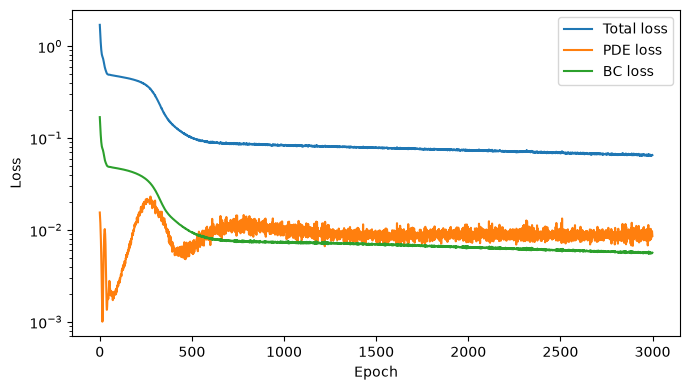

In [ ]:
elapsed = time.perf_counter()-start
print(f"Training time: {elapsed:.1f} seconds")

torch.save(model.state_dict(), "cavity_pinn.pt")

history = torch.tensor(history).numpy()

plt.figure(figsize=(7, 4))
plt.semilogy(history[:, 0], label="Total loss")
plt.semilogy(history[:, 1], label="PDE loss")
plt.semilogy(history[:, 2], label="BC loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig("training_loss.png", dpi=180)
plt.show()

Maximum velocity: 1.0294952
Minimum pressure: -0.15924147
Maximum pressure: 0.11716896


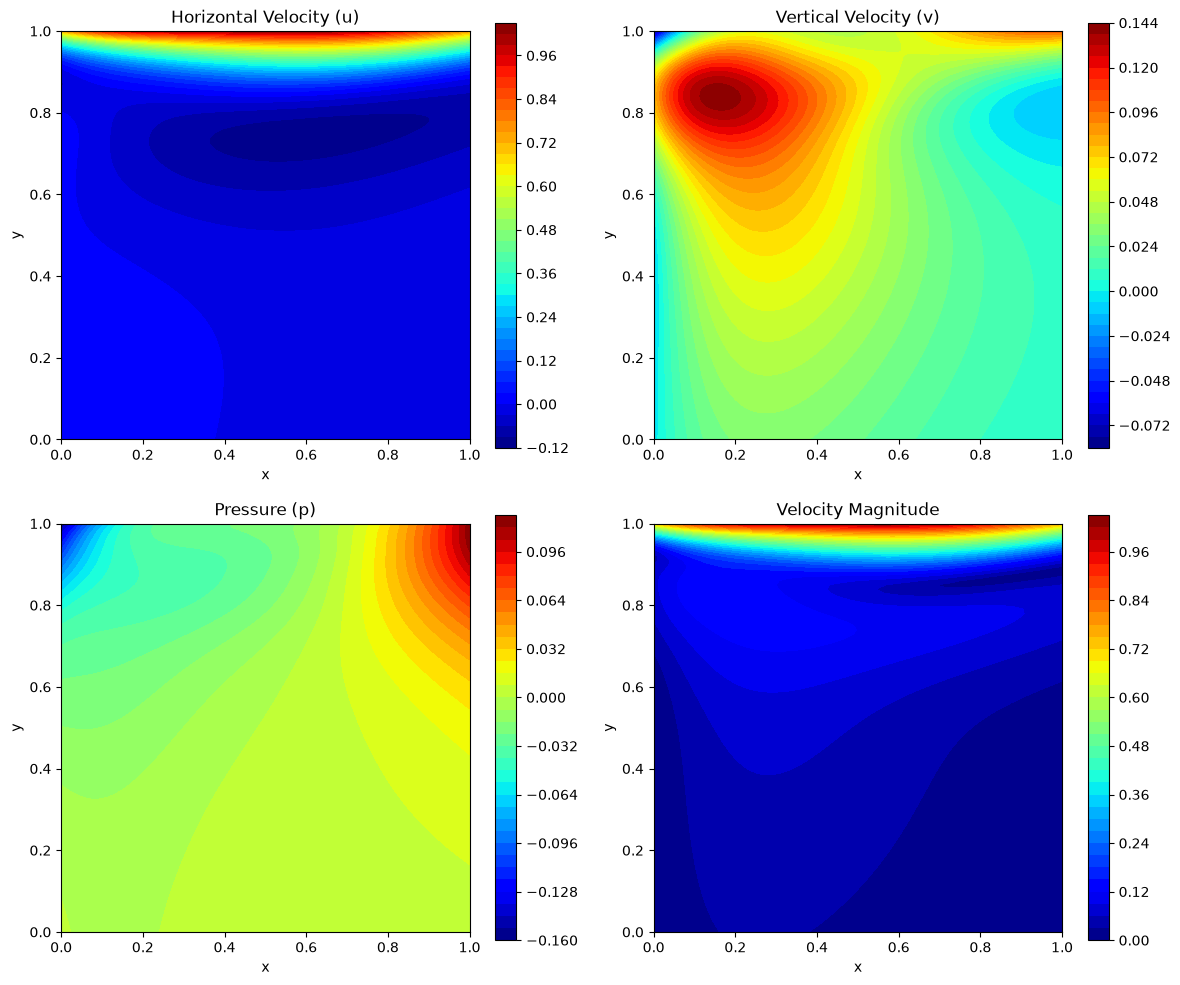

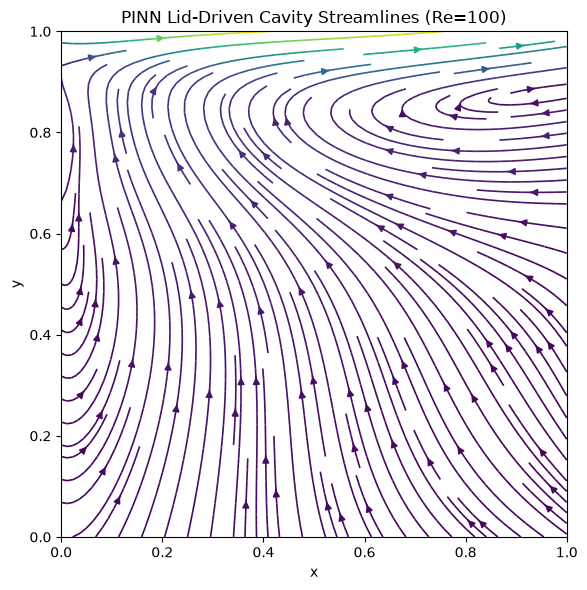

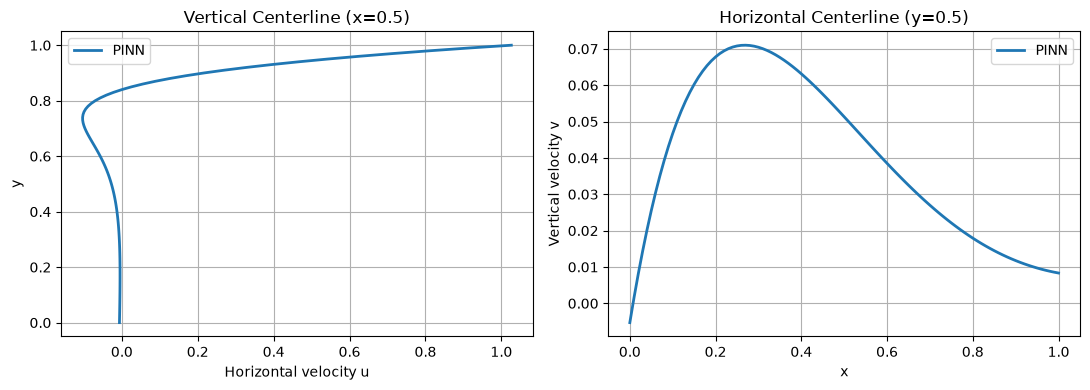

In [17]:

# --------------------------------------------------
# 10. CREATE GRID FOR VISUALIZATION
# --------------------------------------------------

import numpy as np

model.eval()

n_plot = 101

x = np.linspace(0, 1, n_plot)
y = np.linspace(0, 1, n_plot)

X, Y = np.meshgrid(x, y)

# Convert grid coordinates into N x 2 tensor
xy_plot = np.column_stack([
    X.ravel(),
    Y.ravel()
])

xy_tensor = torch.tensor(
    xy_plot,
    dtype=torch.float32,
    device=device
)

# --------------------------------------------------
# 11. PREDICT VELOCITY AND PRESSURE
# --------------------------------------------------

with torch.no_grad():
    prediction = model(xy_tensor)

prediction = prediction.cpu().numpy()

u = prediction[:, 0].reshape(n_plot, n_plot)
v = prediction[:, 1].reshape(n_plot, n_plot)
p = prediction[:, 2].reshape(n_plot, n_plot)

velocity_magnitude = np.sqrt(u**2 + v**2)

print("Maximum velocity:", velocity_magnitude.max())
print("Minimum pressure:", p.min())
print("Maximum pressure:", p.max())

# --------------------------------------------------
# 12. PLOT VELOCITY AND PRESSURE CONTOURS
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

fields = [
    (u, "Horizontal Velocity (u)"),
    (v, "Vertical Velocity (v)"),
    (p, "Pressure (p)"),
    (velocity_magnitude, "Velocity Magnitude")
]

for ax, (field, title) in zip(axes.flat, fields):

    contour = ax.contourf(
        X, Y, field,
        levels=40,
        cmap="jet"
    )

    fig.colorbar(contour, ax=ax)

    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

plt.tight_layout()

plt.savefig(
    "cavity_fields.png",
    dpi=180
)

plt.show()

# --------------------------------------------------
# 13. PLOT STREAMLINES
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

ax.streamplot(
    X, Y,
    u, v,
    density=1.5,
    color=velocity_magnitude,
    cmap="viridis",
    linewidth=1.2
)

ax.set_title(
    f"PINN Lid-Driven Cavity Streamlines (Re={Re:g})"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")

plt.tight_layout()

plt.savefig(
    "cavity_streamlines.png",
    dpi=180
)

plt.show()

# --------------------------------------------------
# 14. EXTRACT CENTERLINE VELOCITY PROFILES
# --------------------------------------------------

# Vertical centerline x = 0.5
u_center = u[:, n_plot // 2]

# Horizontal centerline y = 0.5
v_center = v[n_plot // 2, :]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    u_center, y,
    linewidth=2,
    label="PINN"
)

axes[0].set_xlabel("Horizontal velocity u")
axes[0].set_ylabel("y")
axes[0].set_title("Vertical Centerline (x=0.5)")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(
    x, v_center,
    linewidth=2,
    label="PINN"
)

axes[1].set_xlabel("x")
axes[1].set_ylabel("Vertical velocity v")
axes[1].set_title("Horizontal Centerline (y=0.5)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "cavity_centerlines.png",
    dpi=180
)

plt.show()
